# Deaths on the middle passage, by route and period

How many of the people forced aboard on the African coast died before the ship reached the
Americas, how long the crossing took, and how both changed with the route and over time.

The figures come from the voyages where the database can measure deaths: those with a
recorded number of deaths at sea, or recorded numbers both leaving Africa and arriving. The
database turns those records into an imputed death rate (fields `VYMRTIMP`, deaths, and
`TSLMTIMP`, people embarked; see codebook p. 26). Rates here are pooled: total deaths
divided by total embarked over a group of voyages, so a large voyage counts for more than a
small one.

These voyages are a sample, not the whole trade. A ship lost at sea with everyone aboard
leaves no count of deaths, nor do most voyages of the illegal trade after 1830, so the rates
here are, if anything, too low.

Needs the full data: `uv run voyages fetch && uv run voyages build`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import voyages
from voyages import Voyages

v = Voyages()
measured = v.transatlantic.where("mortality_rate_imputed IS NOT NULL")
rows = measured.to_pandas(
    [
        "voyage_id",
        "embarkation_region_name",
        "disembarkation_region_name",
        "disembarkation_broad_region_name",
        "year_arrived_imputed",
        "embarked_for_mortality_imputed",
        "died_middle_passage_imputed",
        "middle_passage_days_imputed",
        "captives_died_middle_passage",
        "captives_on_board_leaving_africa",
        "captives_arrived_first_landing",
    ]
)
rows["period"] = (rows.year_arrived_imputed - 1) // 25 * 25 + 1  # 1701 = 1701-1725
len(rows), v.transatlantic.count()

(6477, 36108)

How many of these voyages have a recorded basis for the rate: a recorded number of deaths,
or recorded numbers leaving Africa and arriving.

In [2]:
recorded_deaths = rows.captives_died_middle_passage.notna()
recorded_both = (
    rows.captives_on_board_leaving_africa.notna() & rows.captives_arrived_first_landing.notna()
)
basis = pd.crosstab(recorded_deaths.rename("deaths recorded"), recorded_both.rename("both counts"))
basis

both counts,False,True
deaths recorded,,
False,9,2592
True,703,3173


Crossing length is the imputed number of days from leaving Africa to the first landing
(`VOY2IMP`, worked out from recorded dates), known for most but not all of these voyages.
The summary used throughout:

In [3]:
def pooled(group):
    return pd.Series(
        {
            "voyages": len(group),
            "embarked": int(group.embarked_for_mortality_imputed.sum()),
            "died": int(group.died_middle_passage_imputed.sum()),
            "died (%)": round(
                group.died_middle_passage_imputed.sum()
                / group.embarked_for_mortality_imputed.sum()
                * 100,
                1,
            ),
            "median days": group.middle_passage_days_imputed.median(),
            "voyages with days": int(group.middle_passage_days_imputed.notna().sum()),
        }
    )


overall = pooled(rows)
overall

voyages                 6477.0
embarked             2244241.0
died                  277931.0
died (%)                  12.4
median days               50.0
voyages with days       4431.0
dtype: float64

On these 6,477 voyages, about one person in eight died at sea, and the median crossing took
50 days.

## Over time

By quarter-century of arrival, for all voyages and separately for the two largest
destinations, Brazil and the Caribbean, because the mix of routes changed over time and
Brazil's crossings were much shorter. Quarter-centuries with fewer than 20 voyages are
left out.

In [4]:
GROUPS = {
    "All destinations": rows,
    "Caribbean": rows[rows.disembarkation_broad_region_name == "Caribbean"],
    "Brazil": rows[rows.disembarkation_broad_region_name == "Brazil"],
}
by_period = pd.concat(
    {name: g.groupby("period").apply(pooled) for name, g in GROUPS.items()}, names=["group"]
)
by_period = by_period[by_period.voyages >= 20].loc[(slice(None), slice(1651, 1851)), :]
by_period.unstack("group")[["died (%)", "median days"]]

died (%)                       median days                 
group  All destinations Caribbean Brazil All destinations Caribbean Brazil
period                                                                    
1651               26.0      22.8    NaN             93.0      93.0    NaN
1676               23.0      23.1    NaN             75.0      75.0    NaN
1701               17.2      14.9    NaN             71.0      71.0    NaN
1726               15.9      16.3   13.0             67.0      81.0   39.0
1751               13.2      13.0    9.4             69.0      69.0   38.5
1776                9.6       9.6    7.8             52.0      59.0   41.0
1801               10.8      16.8    9.5             43.0      59.0   41.0
1826               10.1      19.4    8.8             34.0      48.0   34.0
1851               18.8      20.0    NaN             45.0      47.0    NaN

- **Losses fell** through the eighteenth century. On Caribbean voyages they fell from about
  23% in 1676–1700 to under 10% in 1776–1800, and the crossing shortened from 75 to 59 days.
- **Brazil** stayed between about 8% and 13%, with crossings of around 40 days.
- **After 1800** the Caribbean rate rose again, to 17–20%, on the voyages of the illegal trade
  to Cuba and Puerto Rico, while the crossing kept getting shorter.

Voyages counted again with the recorded numbers only (left Africa and arrived both recorded)
give almost the same rates:

In [5]:
recorded = (
    v.transatlantic.recorded_only()
    .where(
        "captives_on_board_leaving_africa IS NOT NULL"
        " AND captives_arrived_first_landing IS NOT NULL"
    )
    .to_pandas(["voyage_id", "captives_on_board_leaving_africa", "captives_arrived_first_landing"])
    .merge(rows[["voyage_id", "period"]], on="voyage_id")
)
check = recorded.groupby("period")[
    ["captives_on_board_leaving_africa", "captives_arrived_first_landing"]
].sum()
check["died, recorded (%)"] = (
    (1 - check.captives_arrived_first_landing / check.captives_on_board_leaving_africa) * 100
).round(1)
check["died, imputed rate (%)"] = by_period.loc["All destinations", "died (%)"]
check = check.loc[1676:1826]
check

,captives_on_board_leaving_africa,captives_arrived_first_landing,"died, recorded (%)","died, imputed rate (%)"
period,,,,
1676,70858,54032,23.7,23.0
1701,125216,103482,17.4,17.2
1726,120524,101591,15.7,15.9
1751,271001,236565,12.7,13.2
1776,408808,371749,9.1,9.6
1801,512338,456060,11.0,10.8
1826,407684,365364,10.4,10.1


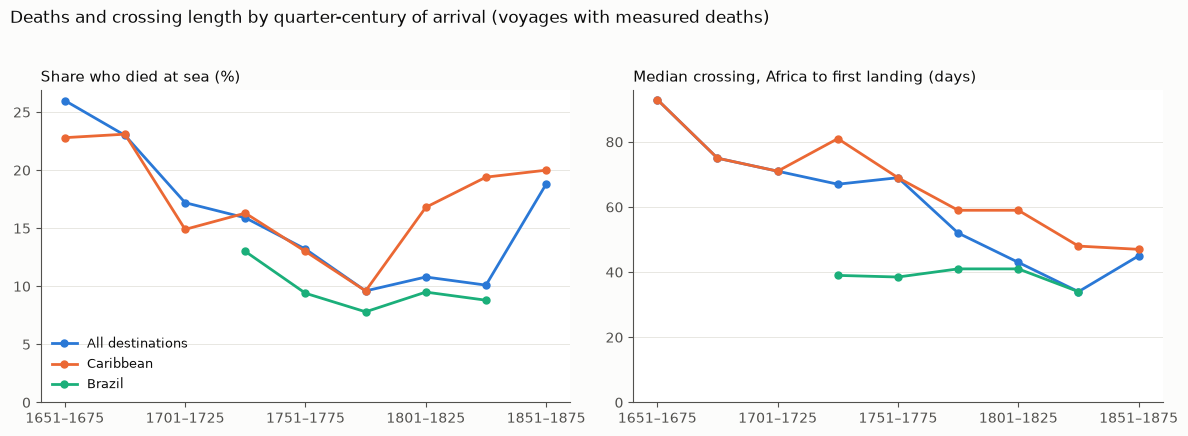

In [6]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3dd"
LINE = {"All destinations": "#2a78d6", "Caribbean": "#eb6834", "Brazil": "#1baf7a"}
plt.rcParams.update({"figure.facecolor": SURFACE, "text.color": INK, "font.size": 10})


def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED)
    ax.yaxis.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True)
for ax, measure, title in zip(
    axes,
    ["died (%)", "median days"],
    ["Share who died at sea (%)", "Median crossing, Africa to first landing (days)"],
    strict=True,
):
    for name, colour in LINE.items():
        s = by_period.loc[name, measure]
        ax.plot(s.index, s.values, color=colour, linewidth=2, marker="o", markersize=5, label=name)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylim(bottom=0)
    style(ax)
ticks = [1651, 1701, 1751, 1801, 1851]
axes[0].set_xticks(ticks, [f"{t}–{t + 24}" for t in ticks])
axes[0].legend(frameon=False, fontsize=9, loc="lower left")
fig.suptitle(
    "Deaths and crossing length by quarter-century of arrival (voyages with measured deaths)",
    x=0.01, ha="left", fontsize=12,
)  # fmt: skip
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("figures/05_deaths_by_period.png", dpi=150)

## Longer crossings, more deaths

Voyages grouped by the length of the crossing. Each extra week at sea meant more deaths from
dysentery, smallpox, scurvy and dehydration. The Bight of Biafra is shown apart from the
other regions because its losses were the highest of the main regions (next section).

In [7]:
BINS = [0, 30, 40, 50, 60, 70, 80, 100, 600]
LABELS = ["30 or less", "31–40", "41–50", "51–60", "61–70", "71–80", "81–100", "over 100"]
with_days = rows.dropna(subset=["middle_passage_days_imputed"]).assign(
    length=lambda d: pd.cut(d.middle_passage_days_imputed, BINS, labels=LABELS),
    coast=lambda d: d.embarkation_region_name.map(
        lambda r: "Bight of Biafra" if r.startswith("Bight of Biafra") else "Other regions"
    ),
)
by_length = with_days.groupby(["length", "coast"], observed=True).apply(pooled)
by_length_all = with_days.groupby("length", observed=True).apply(pooled)
by_length.unstack("coast")[["voyages", "died (%)"]]

voyages                      died (%)              
coast      Bight of Biafra Other regions Bight of Biafra Other regions
length                                                                
30 or less            51.0         545.0            11.6           5.6
31–40                 64.0         854.0            18.3           7.4
41–50                 42.0         679.0            12.3           8.5
51–60                 70.0         519.0            14.8          10.0
61–70                 59.0         417.0            11.0           9.9
71–80                 42.0         321.0            17.4          13.4
81–100                30.0         358.0            26.5          15.8
over 100              30.0         350.0            35.5          20.5

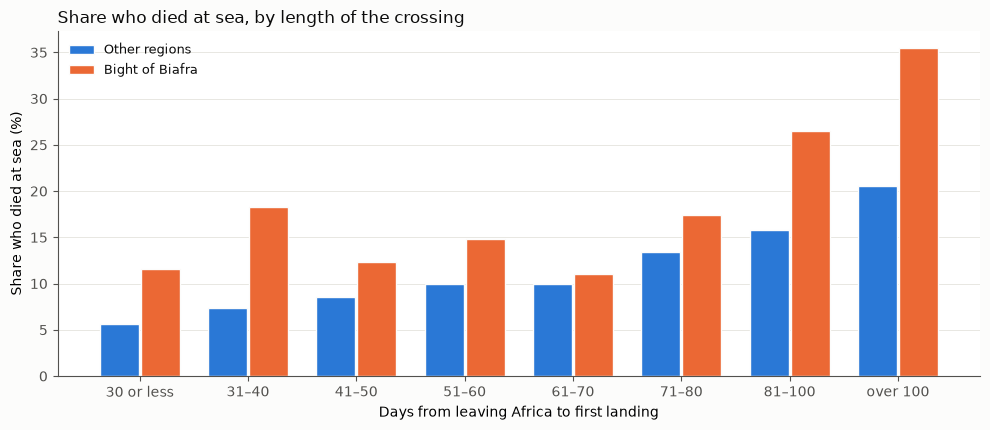

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.4))
COAST = {"Other regions": "#2a78d6", "Bight of Biafra": "#eb6834"}
x = range(len(LABELS))
for i, (coast, colour) in enumerate(COAST.items()):
    rate = by_length.xs(coast, level="coast")["died (%)"].reindex(LABELS)
    ax.bar(
        [p + (i - 0.5) * 0.38 for p in x], rate.values, width=0.36, color=colour,
        edgecolor=SURFACE, linewidth=1, label=coast,
    )  # fmt: skip
ax.set_xticks(list(x), LABELS)
ax.set_xlabel("Days from leaving Africa to first landing")
ax.set_ylabel("Share who died at sea (%)")
ax.set_title("Share who died at sea, by length of the crossing", loc="left")
ax.legend(frameon=False, fontsize=9, loc="upper left")
style(ax)
fig.tight_layout()
fig.savefig("figures/05_deaths_by_length.png", dpi=150)

For all regions together, the rate rises from 6% on crossings of a month or less to 21% on
crossings of more than a hundred days. For crossings of every length, more people died on
ships from the Bight of Biafra than on ships from other regions, so length alone does not
explain that coast's higher losses.

## By African region

In [9]:
by_region = rows.groupby("embarkation_region_name").apply(pooled).sort_values("died (%)")
by_region

,voyages,embarked,died,died (%),median days,voyages with days
embarkation_region_name,,,,,,
West Central Africa and St. Helena,2469.0,1021738.0,95179.0,9.3,40.0,1789.0
Windward Coast,140.0,30926.0,2982.0,9.6,62.0,95.0
Sierra Leone,237.0,47711.0,4998.0,10.5,45.0,113.0
Senegambia and offshore Atlantic,431.0,83171.0,9435.0,11.3,41.0,267.0
Gold Coast,654.0,180705.0,22659.0,12.5,70.0,425.0
Bight of Benin,1204.0,422734.0,53470.0,12.6,62.0,972.0
Southeast Africa and Indian Ocean islands,359.0,177011.0,33945.0,19.2,65.0,278.0
Bight of Biafra and Gulf of Guinea islands,662.0,200631.0,39186.0,19.5,56.0,388.0
Other Africa,319.0,79374.0,15973.0,20.1,67.5,104.0


West Central Africa (Angola and the Congo), the largest region, had the lowest rate, and
most of its captives went on the short crossing to Brazil. The Bight of Biafra and
Southeast Africa (Mozambique, whose ships rounded the Cape of Good Hope) had the highest,
about one in five.

## By route

African region to broad region of landing, for routes with at least 100 voyages and at
least 50 with a known crossing length. "Other Africa" (region not known) and landings back in
Africa are left out. The second group are mostly ships seized by the Royal Navy after
1807, whose captives were landed at Sierra Leone.

In [10]:
SHORT = {
    "West Central Africa and St. Helena": "West Central Africa",
    "Bight of Biafra and Gulf of Guinea islands": "Bight of Biafra",
    "Senegambia and offshore Atlantic": "Senegambia",
    "Southeast Africa and Indian Ocean islands": "Southeast Africa",
}
by_route = rows.groupby(["embarkation_region_name", "disembarkation_broad_region_name"]).apply(
    pooled
)
routes = by_route[(by_route.voyages >= 100) & (by_route["voyages with days"] >= 50)]
routes = routes[
    (routes.index.get_level_values(0) != "Other Africa")
    & (routes.index.get_level_values(1) != "Africa")
].sort_values("median days")
routes.index = [f"{SHORT.get(a, a)} → {b}" for a, b in routes.index]
routes

,voyages,embarked,died,died (%),median days,voyages with days
West Central Africa → Brazil,1610.0,696040.0,56043.0,8.1,35.0,1228.0
Senegambia → Brazil,111.0,17903.0,1350.0,7.5,36.5,52.0
Senegambia → Caribbean,213.0,47855.0,5207.0,10.9,38.0,156.0
Sierra Leone → Caribbean,152.0,33719.0,3143.0,9.3,44.0,83.0
Bight of Benin → Brazil,413.0,129127.0,8383.0,6.5,44.5,354.0
West Central Africa → Caribbean,627.0,244086.0,23738.0,9.7,61.0,482.0
Windward Coast → Caribbean,121.0,28892.0,2827.0,9.8,62.0,84.0
Southeast Africa → Brazil,265.0,137368.0,22778.0,16.6,63.0,226.0
Bight of Biafra → Caribbean,442.0,139071.0,25918.0,18.6,65.0,236.0
Gold Coast → Caribbean,564.0,163552.0,19390.0,11.9,70.0,353.0


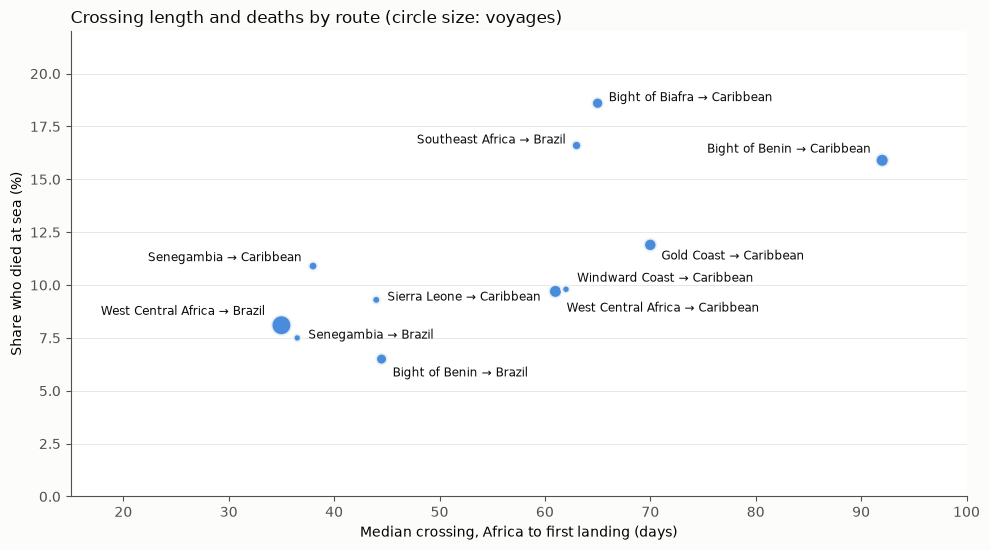

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.scatter(
    routes["median days"], routes["died (%)"], s=20 + routes.voyages / 8, color="#2a78d6",
    alpha=0.85, edgecolor=SURFACE, linewidth=2, zorder=3,
)  # fmt: skip
# Hand-placed labels: (dx, dy) in points, and alignment.
OFFSET = {
    "West Central Africa → Brazil": (-12, 10, "right"),
    "Senegambia → Brazil": (8, 2, "left"),
    "Senegambia → Caribbean": (-8, 6, "right"),
    "Sierra Leone → Caribbean": (8, 2, "left"),
    "Bight of Benin → Brazil": (8, -10, "left"),
    "West Central Africa → Caribbean": (8, -12, "left"),
    "Windward Coast → Caribbean": (8, 8, "left"),
    "Southeast Africa → Brazil": (-8, 4, "right"),
    "Bight of Biafra → Caribbean": (8, 4, "left"),
    "Gold Coast → Caribbean": (8, -8, "left"),
    "Bight of Benin → Caribbean": (-8, 8, "right"),
}
for route, r in routes.iterrows():
    dx, dy, ha = OFFSET.get(route, (8, 0, "left"))
    ax.annotate(
        route, (r["median days"], r["died (%)"]), xytext=(dx, dy), textcoords="offset points",
        ha=ha, va="center", fontsize=8.5, color=INK,
    )  # fmt: skip
ax.set_xlabel("Median crossing, Africa to first landing (days)")
ax.set_ylabel("Share who died at sea (%)")
ax.set_xlim(15, 100)
ax.set_ylim(0, 22)
ax.set_title("Crossing length and deaths by route (circle size: voyages)", loc="left")
style(ax)
fig.tight_layout()
fig.savefig("figures/05_routes.png", dpi=150)

The shortest routes, about five weeks, were from West Central Africa and Senegambia to
Brazil and from Senegambia to the Caribbean, and they were among the least deadly. The
same coast could give very
different crossings: ships from the Bight of Benin took a median 45 days to Brazil, where
6.5% died, and 92 days to the Caribbean, where 16% died. The Bight of Biafra to the
Caribbean was shorter than that but deadlier, at about 19%.

## Voyages to Jamaica

The same measures for voyages whose principal place of landing was in Jamaica.

In [12]:
jamaica = rows[rows.disembarkation_region_name == "Jamaica"]
jamaica_overall = pooled(jamaica)
jamaica_by_period = jamaica.groupby("period").apply(pooled).query("voyages >= 20")
jamaica_by_region = jamaica.groupby("embarkation_region_name").apply(pooled).query("voyages >= 50")
jamaica_overall

voyages                 582.0
embarked             197859.0
died                  22757.0
died (%)                 11.5
median days              63.0
voyages with days       407.0
dtype: float64

In [13]:
jamaica_by_period

,voyages,embarked,died,died (%),median days,voyages with days
period,,,,,,
1676,44.0,17686.0,5109.0,28.9,90.0,24.0
1701,69.0,23672.0,3325.0,14.0,68.5,54.0
1751,115.0,33908.0,4524.0,13.3,74.0,51.0
1776,327.0,113412.0,7951.0,7.0,59.5,268.0


In [14]:
jamaica_by_region.sort_values("died (%)")

,voyages,embarked,died,died (%),median days,voyages with days
embarkation_region_name,,,,,,
West Central Africa and St. Helena,86.0,30081.0,1824.0,6.1,53.0,64.0
Gold Coast,201.0,67009.0,5385.0,8.0,66.0,157.0
Bight of Biafra and Gulf of Guinea islands,127.0,45125.0,6639.0,14.7,64.0,82.0
Bight of Benin,81.0,33588.0,6429.0,19.1,78.0,49.0


On the 582 voyages to Jamaica with measured deaths, 11.5% of the people aboard died at sea.
The rate fell from 29% in 1676–1700 to 7% in 1776–1800. Ships from the Bight of Biafra lost
14.7% and ships from the Gold Coast 8.0%.

Notebook 02 gives 14.0% for all voyages to Jamaica. That figure is the imputed number
embarked less the imputed number landed, over every voyage, so it includes voyages whose
losses were filled in from group averages. The 11.5% here uses only voyages whose deaths
can be measured.

## Checks

The figures quoted above, checked against the tables.

In [15]:
assert (len(rows), overall["died (%)"], overall["median days"]) == (6_477, 12.4, 50.0)
assert (~recorded_deaths & ~recorded_both).sum() == 9
cb = by_period.loc["Caribbean"]
assert (cb.loc[1676, "died (%)"], cb.loc[1776, "died (%)"]) == (23.1, 9.6)
assert (cb.loc[1676, "median days"], cb.loc[1776, "median days"]) == (75.0, 59.0)
assert cb.loc[1801:1851, "died (%)"].between(16.5, 20.0).all()
assert by_period.loc["Brazil"].loc[1701:1826, "died (%)"].between(7.5, 13.5).all()
assert (check["died, recorded (%)"] - check["died, imputed rate (%)"]).abs().max() <= 1.0
assert by_length_all.loc["30 or less", "died (%)"] == 6.0
assert by_length_all.loc["over 100", "died (%)"] == 21.3
rates = by_length["died (%)"].unstack("coast")
assert (rates["Bight of Biafra"] > rates["Other regions"]).all()
assert by_region.index[0] == "West Central Africa and St. Helena"
assert set(by_region.index[-3:]) == {
    "Southeast Africa and Indian Ocean islands",
    "Bight of Biafra and Gulf of Guinea islands",
    "Other Africa",
}
assert by_region.loc["Bight of Biafra and Gulf of Guinea islands", "died (%)"] == 19.5
benin_brazil, benin_carib = (
    routes.loc["Bight of Benin → Brazil"],
    routes.loc["Bight of Benin → Caribbean"],
)
assert (benin_brazil["median days"], benin_brazil["died (%)"]) == (44.5, 6.5)
assert (benin_carib["median days"], benin_carib["died (%)"]) == (92.0, 15.9)
assert routes.loc["Bight of Biafra → Caribbean", "died (%)"] == 18.6
assert set(routes.index[:3]) == {
    "West Central Africa → Brazil",
    "Senegambia → Brazil",
    "Senegambia → Caribbean",
}
assert set(routes.index) == set(OFFSET), set(routes.index) ^ set(OFFSET)
assert (jamaica_overall.voyages, jamaica_overall["died (%)"]) == (582, 11.5)
assert jamaica_by_period.loc[[1676, 1776], "died (%)"].tolist() == [28.9, 7.0]
assert jamaica_by_region.loc[
    ["Bight of Biafra and Gulf of Guinea islands", "Gold Coast"], "died (%)"
].tolist() == [14.7, 8.0]

In [16]:
voyages.citation()

'SlaveVoyages, Trans-Atlantic Slave Trade Database, https://www.slavevoyages.org (accessed October 19, 2026).'